In [3]:
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, PdfFormatOption
from IPython.display import display
import openai
import getpass
import base64
import io
from groq import Groq
from pydantic import BaseModel
from datetime import datetime
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
import os

In [4]:
#Define PDF conversion
pipeline_options = PdfPipelineOptions()
pipeline_options.images_scale = 2
pipeline_options.generate_page_images =True

In [5]:
#Intialize the converter with these options
document_conveter = DocumentConverter(
    format_options = {InputFormat.PDF : PdfFormatOption(pipeline_options=pipeline_options)}
)

In [20]:
#Run the conversation
source = "/home/houssem_mabrouk/projects/prompt_chaining_task_routing/pdf_invoice.pdf"
result = document_conveter.convert(source)

/home/houssem_mabrouk/projects/prompt_chaining_task_routing/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 770/770 [00:01<00:00, 527.13it/s] 


In [6]:
#set up openAI / groq API
api_key = getpass.getpass("Enter your API key:")
client = Groq(api_key = api_key)

In [7]:
class InvoiceNumber(BaseModel):
    invoice_number: str


class BalanceDue(BaseModel):
    balance_due: str



class InvoiceDate(BaseModel):
    invoice_date: datetime

class ShippingAddress(BaseModel):
    street:str
    city:str
    state:str
    zip_code:str
    country:str

In [50]:
def ask_question(
    user_content,
    response_model,
    instructions="You are a helpful assistant. Return valid JSON."
):
    response = client.chat.completions.create(
        model="qwen/qwen3.8-27b",
        messages=[
            {"role": "system", "content": instructions},
            {"role": "user", "content": user_content}
        ],
        response_format={"type": "json_object"},
        temperature=0
    )

    result = response.choices[0].message.content

    return response_model.model_validate_json(
        result,
        by_alias=True,
        by_name=True
    )

In [38]:
from typing import Any
class InvoiceState(TypedDict):
    doc:Any
    invoice_number: InvoiceNumber
    balance_due: BalanceDue
    invoice_date: InvoiceDate
    shipping_address: ShippingAddress
    high_value:bool

In [52]:
def extract_attributes(state: InvoiceState) -> InvoiceState:
    # Extract text and images from the Docling document
    doc = state["doc"]
    text = doc.export_to_markdown()

    # Extract invoice number and balance due from text
    invoice_number = ask_question(
        f"Extract the invoice number from the text.\nText: {text}",
        InvoiceNumber
    )

    balance_due = ask_question(
        f"Extract the balance due from the text.\nText: {text}",
        BalanceDue
    )

    # Helper function to encode a page image
    def encode_image(page):
        buffered = io.BytesIO()
        doc.pages[page].image.pil_image.save(buffered, format="PNG")
        return base64.b64encode(buffered.getvalue()).decode("utf-8")

    # Encode the first page (index 0)
    base64_string = encode_image(0)

    # Extract invoice date from image
    invoice_date = ask_question(
        [
            {
                "type": "text",
                "text": f"Extract the invoice date from this image. Return valid JSON.\nText: {text}"
            },
            {
                "type": "image_url",
                "image_url": {
                    "url": f"data:image/png;base64,{base64_string}"
                }
            }
        ],
        InvoiceDate
    )

    # Extract shipping address from text and image
    shipping_address = ask_question(
        [
            {
                "type": "text",
                "text": f"Extract the shipping address. Return valid JSON.\nText: {text}"
            },
            {
                "type": "image_url",
                "image_url": {
                    "url": f"data:image/png;base64,{base64_string}"
                }
            }
        ],
        ShippingAddress
    )

    return {
        "doc": doc,
        "invoice_number": invoice_number.invoice_number,
        "balance_due": balance_due.balance_due,
        "invoice_date": invoice_date.invoice_date,
        "shipping_address": shipping_address
    }

In [45]:
def check_amount(state : InvoiceState)->InvoiceState:
    state["high_value"] = state["balance_due"] > 5000
    return state

def low_value_invoice(state:InvoiceState):
    print("low value invoice - proceed to automated processing")


def high_value_invoice(state:InvoiceState):
    print("high value invoice - route to lanual handling")

In [46]:
#Build the state graph:nodes represent steps , edges represent tranitions 
graph = StateGraph(InvoiceState)
graph.add_node("extract",extract_attributes)
graph.add_node("check",check_amount)
graph.add_node("low_value",low_value_invoice)
graph.add_node("high_value",high_value_invoice)
graph.add_edge(START,"extract")
graph.add_edge("extract","check")
graph.add_conditional_edges("check",lambda state :"high_value" if state["high_value"] else "low_value",{"high_value" :"high_value","low_value" :"low_value"})
graph.add_edge("low_value",END)
graph.add_edge("high_value",END)


In [53]:
#compile the graph
app = graph.compile()

#invoke the graph with an intially blank state
result = app.invoke({"doc":result.document})
#observe the result object
result

BadRequestError: Error code: 400 - {'error': {'message': "'messages.1' : for 'role:user' the following must be satisfied[('messages.1.content' : one of the following must be satisfied[('messages.1.content' : value must be a string) OR ('messages.1.content.0' : one of the following must be satisfied[('messages.1.content.0.type' : property 'type' is missing) OR ('messages.1.content.0.type' : property 'type' is missing) OR ('messages.1.content.0.type' : property 'type' is missing)])])]", 'type': 'invalid_request_error'}}

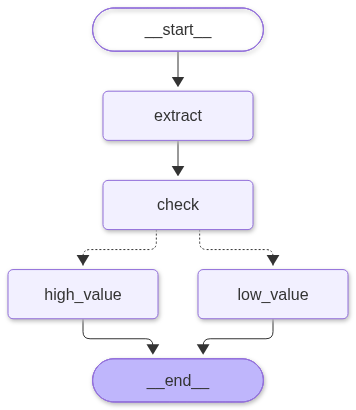

In [55]:
from IPython.display import Image,display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
#Launch a local app for quick visualization
import phoenix as px
px.launch_app()
session = px.launch_app()

#Example instrumentation : register OpenTelemetry exports and instrumentors
from phoenix.otel import register
register()

#Enable the langchain instrumentor to automatically capture traces/metrics 
from openinference.instrumentation.langchain import LangChainInstrumentor
LangChainInstrumentor().instument()

# run the graph to collect traces/metrics locally
result = app.invoke({"doc":result.document})
print(result)


AttributeError: module 'phoenix' has no attribute 'launch_app'

In [2]:
%pip install langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 591.1/591.1 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 11.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [langgraph]16 [langgraph]checkpoint]
Note: you may need to restart the kernel to use updated packages.


In [57]:
%pip install arize-phoenix-otel openinference-instrumentation-langchain

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 10.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19/19 [arize-phoenix-otel]pentelemetry-exporter-otlp]]
Note: you may need to restart the kernel to use updated packages.


In [60]:
%pip uninstall -y arize-phoenix
%pip install --upgrade arize-phoenix

Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 11.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 10.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 11.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 763.9/763.9 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 11.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.9/16.9 MB 11.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 11.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 11.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━